# Dependencies

In [1]:
import numpy as np
import scipy as sp
import netCDF4 as nC4
import scipy.signal
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sn
import eofs
import xrft
from cdo import Cdo
cdo = Cdo(tempdir='/network/aopp/chaos/pred/leach/.cdo_temp_files')
# uncomment the below if you want to clean up the temporary directory
# cdo.cleanTempDir()
import cartopy
from cartopy import crs
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import xarray as xr
import regionmask
import xskillscore as xs
import pandas as pd
import sys
import glob
import datetime
import time
import multiprocessing
import tqdm
import cmocean
import palettable
from shapely.geometry.polygon import LinearRing
import copy
import shutil
import gzip

sys.path.append('/home/l/leach/Downloads/')
import ScientificColourMaps6 as SCM6

from IPython.display import display, clear_output

## get FaIR
from fair import *

## get my stats functions
from mystatsfunctions import OLSE,LMoments
from moarpalettes import get_palette

## matplotlib rcParams
## IF you want to use thesis style

import requests
from io import StringIO, BytesIO

req = requests.get('https://raw.githubusercontent.com/njleach/Thesis/main/ancil/figure-style.mplstyle')

with open("/home/l/leach/thesis.mplstyle", "w") as text_file:
    text_file.write(req.content.decode())
    
plt.style.use("/home/l/leach/thesis.mplstyle")
textwidth = matplotlib.rcParams['figure.figsize'][0]

%matplotlib inline

# Import data

In [2]:
ds = xr.open_dataset('/gf3/predict2/AWH009_LEACH_RELIABLE/COUNTERFACTUAL-FORECASTING/DATA/postproc/figure-data/perturbed_restarts_025deg.nc')

# Create plot

In [3]:
## select perturbation to use
ds_plot = ds.sel(inidate='JUNE',rtype='obs-delta') - ds.sel(inidate='JUNE',rtype='operational')

/home/l/leach/installed-packages/miniconda3/lib/python3.7/site-packages/ipykernel_launcher.py:68: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


[None, None]

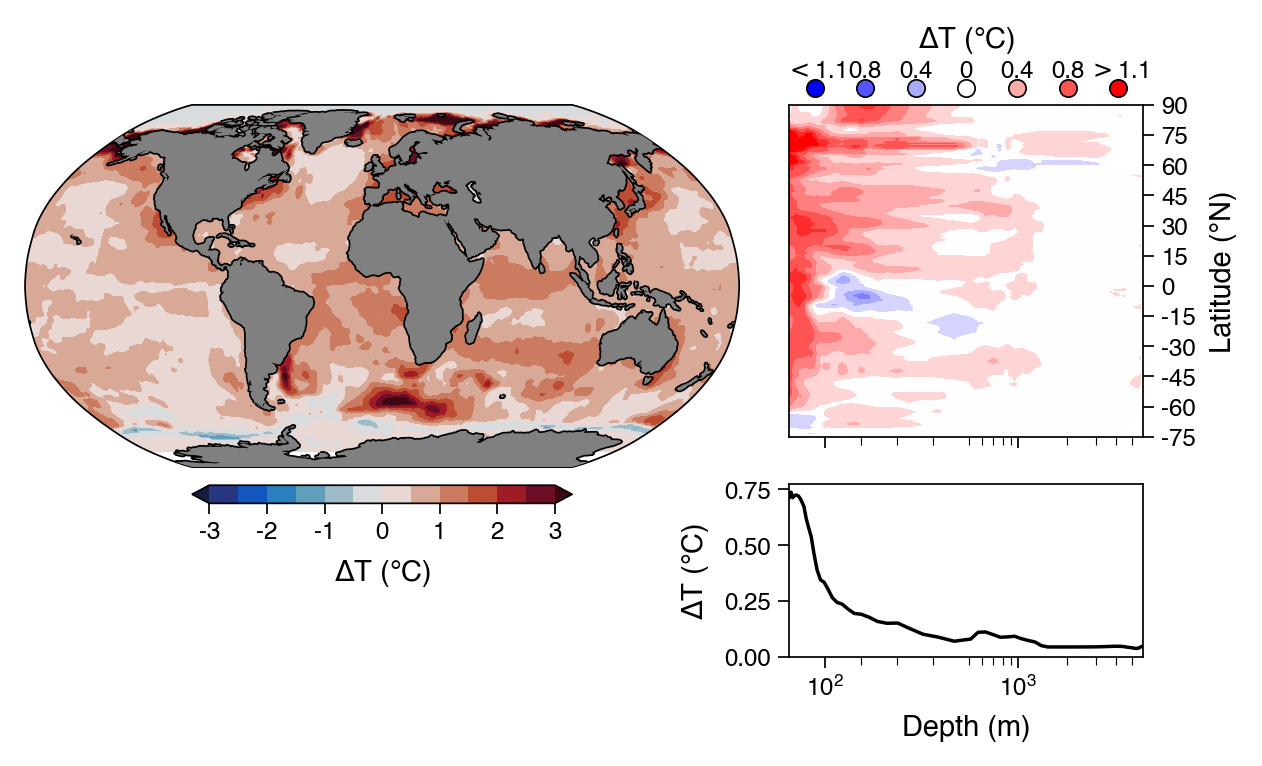

In [5]:
fig = plt.figure()

gs = fig.add_gridspec(3,3,wspace=0.1,hspace=0.1)
ax_map = fig.add_subplot(gs[:2,:-1],projection=crs.Robinson())
# sneakily make the lat axes 1/18 smaller so only need to plot to -80
gslat = matplotlib.gridspec.GridSpecFromSubplotSpec(36,1,subplot_spec=gs[:2,-1])
ax_lat = fig.add_subplot(gslat[:-3])
ax_z = fig.add_subplot(gs[2:,-1])
# ax_z1 = ax_z.twinx()

## plot map
p_map = ds_plot.tn.isel(z=0).squeeze().plot.contourf(ax=ax_map,cmap=cmocean.cm.balance,levels=np.linspace(-3,3,13),extend='both',transform=crs.PlateCarree(),add_colorbar=False)

## plot depth
p_lat = ds_plot.sel(lat=slice(-75,90)).where(ds.tmask).tn.mean('lon').squeeze().T.plot.contourf(ax=ax_lat,cmap='bwr',extend='both',levels=np.linspace(-1.1,1.1,12),add_colorbar=False)

## plot line
p_z = ds_plot.where(ds.tmask).tn.weighted(np.cos(np.deg2rad(ds_plot.lat)).clip(0,1)).mean(['lat','lon']).plot(ax=ax_z,color='k')
# p_z = ds_plot.where(ds.tmask).sn.weighted(np.cos(np.deg2rad(ds_plot.lat)).clip(0,1)).mean(['lat','lon']).plot(ax=ax_z1,color='k')

# axes layout
## all
[a.set_title('') for a in [ax_map,ax_lat,ax_z]]
[a.set_xscale('symlog',linthresh=500,linscale=1,base=10,subs=[2,3,4,5,6,7,8,9]) for a in [ax_lat,ax_z]]
[a.set_xlim(ds_plot.z.min(),ds_plot.z.max()) for a in [ax_lat,ax_z]]
# [a.set_xticks([100,200,300,400,500,1000,2000,4000]) for a in [ax_lat,ax_z]]
[a.tick_params(axis='both',labelsize='x-small') for a in [ax_lat,ax_z]]

## map
ax_map.add_feature(cfeature.NaturalEarthFeature('physical', 'land', '110m'),color='grey',zorder=3,lw=0)
ax_map.coastlines('110m',lw=1)

inset = ax_map.inset_axes([0+(1-0.5322)/2,-0.1,0.5322,0.05],transform=ax_map.transAxes)
cbar = plt.colorbar(p_map,cax=inset, orientation='horizontal')
cbar.set_label('$\Delta$T (\N{DEGREE SIGN}C)',fontsize='small')
cbar.ax.tick_params(axis='both',labelsize='x-small')

## lat
ax_lat.set_xticklabels([])
ax_lat.set_xlabel('')
ax_lat.set_yticks(np.arange(-75,91,15))
ax_lat.set_ylim(-75,90)
ax_lat.yaxis.tick_right()
ax_lat.yaxis.set_label_position("right")
ax_lat.set_ylabel('Latitude (\N{DEGREE SIGN}N)',fontsize='small')

### generate a funky colorbar
lat_cmap = p_lat.cmap.colors
lat_cmap = [p_lat.cmap._rgba_under] + lat_cmap + [p_lat.cmap._rgba_over]
lat_cmap = lat_cmap[::2]
lat_levels = ['$<$1.1','','0.8','','0.4','','0','','0.4','','0.8','','$>$1.1'][::2]
[ax_lat.plot(i/len(lat_cmap)+0.5/len(lat_cmap),1.05,'o',transform=ax_lat.transAxes,color=x,clip_on=False,mec='k',ms=5) for i,x in enumerate(lat_cmap)]
[ax_lat.text(i/len(lat_cmap)+0.5/len(lat_cmap),1.07,lat_levels[i],transform=ax_lat.transAxes,va='bottom',ha='center',fontsize='x-small') for i,x in enumerate(lat_cmap)]
ax_lat.text(0.5,1.15,'$\Delta$T (\N{DEGREE SIGN}C)',transform=ax_lat.transAxes,fontsize='small',ha='center',va='bottom')

## z
ax_z.set_yticks([0,0.25,0.5,0.75])
# ax_z.yaxis.tick_right()
# ax_z.yaxis.set_label_position("right")
ax_z.set_ylabel('$\Delta$T (\N{DEGREE SIGN}C)',fontsize='small')
ax_z.set_xlabel('Depth (m)',fontsize='small')

# fig layout
fig_aspect = 1/2
fig.patch.set_facecolor('xkcd:white')
fig.set_size_inches(textwidth,textwidth*fig_aspect)
fig.dpi=250
plt.tight_layout(w_pad=1)

[fig.savefig('../output/figs/manuscript-figs/FIGS1.'+x,dpi=600,bbox_inches='tight') for x in ['png','pdf']]